# Assignment 10

In [1]:
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.MolStandardize import rdMolStandardize

from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    XGBRegressor = None
    HAS_XGB = False
    warnings.warn("xgboost is not installed; XGBoost cells will be skipped.")


In [2]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

In [3]:
TARGET_ID = "CHEMBL217"
MAX_ACTIVITY_ROWS = 5000
RAW_ACTIVITY_PATH = Path(f"data/{TARGET_ID}/chembl_herg_ic50_raw.csv")

print("Target:", TARGET_ID)
print("Activity cache:", RAW_ACTIVITY_PATH)

Target: CHEMBL217
Activity cache: data/CHEMBL217/chembl_herg_ic50_raw.csv


In [4]:
if RAW_ACTIVITY_PATH.exists():
    activities = pd.read_csv(RAW_ACTIVITY_PATH)
    print(f"Loaded cached activity table: {RAW_ACTIVITY_PATH}")
else:
    from chembl_webresource_client.new_client import new_client

    activity = new_client.activity
    query = activity.filter(
        target_chembl_id=TARGET_ID,
        standard_type="IC50",
    ).only(
        "molecule_chembl_id", "standard_value", "standard_units",
        "standard_relation", "assay_chembl_id", "assay_type",
        "target_chembl_id", "pchembl_value", "confidence_score",
    )

    RAW_ACTIVITY_PATH.parent.mkdir(exist_ok=True, parents=True)

    activities = pd.DataFrame(list(query[:MAX_ACTIVITY_ROWS]))
    activities.to_csv(RAW_ACTIVITY_PATH, index=False)
    print(f"Retrieved and cached {len(activities):,} activity rows.")


Loaded cached activity table: data/CHEMBL217/chembl_herg_ic50_raw.csv


In [5]:
print("Activity query provenance:")
print({
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "requested_fields": [
        "molecule_chembl_id", "standard_value", "standard_units",
        "standard_relation", "assay_chembl_id", "assay_type",
        "target_chembl_id", "pchembl_value", "confidence_score",
    ],
    "row_interpretation": "one activity observation, not one unique molecule",
})
print("Activity rows:", len(activities))
print("Unique molecules:", activities["molecule_chembl_id"].nunique())
print("Unique assays:", activities["assay_chembl_id"].nunique())

Activity query provenance:
{'target_chembl_id': 'CHEMBL217', 'standard_type': 'IC50', 'requested_fields': ['molecule_chembl_id', 'standard_value', 'standard_units', 'standard_relation', 'assay_chembl_id', 'assay_type', 'target_chembl_id', 'pchembl_value', 'confidence_score'], 'row_interpretation': 'one activity observation, not one unique molecule'}
Activity rows: 2480
Unique molecules: 2157
Unique assays: 204


In [6]:
print("shape:", activities.shape)
display(activities.head())
display(activities.dtypes.rename("dtype").to_frame())


shape: (2480, 12)


,assay_chembl_id,assay_type,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_units,standard_value,target_chembl_id,type,units,value
0,CHEMBL671073,B,CHEMBL303519,5.01,=,=,nM,9800.0,CHEMBL217,IC50,nM,9800.0
1,CHEMBL671073,B,CHEMBL292943,7.30,=,=,nM,50.0,CHEMBL217,IC50,nM,50.0
2,CHEMBL671073,B,CHEMBL61682,7.60,=,=,nM,25.0,CHEMBL217,IC50,nM,25.0
3,CHEMBL671073,B,CHEMBL64487,6.44,=,=,nM,360.0,CHEMBL217,IC50,nM,360.0
4,CHEMBL671073,B,CHEMBL64597,6.52,=,=,nM,300.0,CHEMBL217,IC50,nM,300.0


,dtype
assay_chembl_id,object
assay_type,object
molecule_chembl_id,object
pchembl_value,float64
relation,object
standard_relation,object
standard_units,object
standard_value,float64
target_chembl_id,object
type,object


In [7]:
print("Units:")
display(activities["standard_units"].value_counts(dropna=False).head(10))

print("Relations:")
display(activities["standard_relation"].value_counts(dropna=False))


Units:


standard_units
nM     1585
NaN     895
Name: count, dtype: int64

Relations:


standard_relation
=      1100
NaN     907
>       466
<         7
Name: count, dtype: int64

In [8]:
STRUCTURE_CACHE = Path(f"data/{TARGET_ID}/chembl_herg_structures.csv")
print("Structure cache:", STRUCTURE_CACHE)

Structure cache: data/CHEMBL217/chembl_herg_structures.csv


In [9]:
if STRUCTURE_CACHE.exists():
    structures = pd.read_csv(STRUCTURE_CACHE)
    print(f"Loaded cached structures: {STRUCTURE_CACHE}")
else:
    from chembl_webresource_client.new_client import new_client

    molecule = new_client.molecule
    unique_ids = activities["molecule_chembl_id"].dropna().astype(str).unique().tolist()
    records = []
    for position, chembl_id in enumerate(unique_ids, start=1):
        record = molecule.get(chembl_id)
        molecule_structures = record.get("molecule_structures") or {}
        records.append({
            "molecule_chembl_id": chembl_id,
            "canonical_smiles": molecule_structures.get("canonical_smiles"),
        })
        if position % 100 == 0:
            print(f"Retrieved {position}/{len(unique_ids)} structures")
    structures = pd.DataFrame(records)
    structures.to_csv(STRUCTURE_CACHE, index=False)

Loaded cached structures: data/CHEMBL217/chembl_herg_structures.csv


In [10]:
df = activities.merge(structures, on="molecule_chembl_id", how="left")

print("merged shape:", df.shape)
print("missing canonical SMILES:", int(df["canonical_smiles"].isna().sum()))
display(df[["molecule_chembl_id", "standard_value", "canonical_smiles"]].head())

merged shape: (2480, 13)
missing canonical SMILES: 38


,molecule_chembl_id,standard_value,canonical_smiles
0,CHEMBL303519,9800.0,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1
1,CHEMBL292943,50.0,COc1ccc(-c2cccc(CN3CCN(c4ncccn4)CC3)c2)cc1
2,CHEMBL61682,25.0,Fc1ccc(-c2cncc(CN3CCN(c4ccccc4F)CC3)c2)cc1
3,CHEMBL64487,360.0,COc1ccccc1-c1cccc(CN2CCN(c3ncccn3)CC2)c1
4,CHEMBL64597,300.0,c1cnc(N2CCN(Cc3cccc(-c4ccsc4)c3)CC2)nc1


In [11]:
CHEMBL_NAME_CACHE = Path(f"data/{TARGET_ID}/chembl_molecule_names.csv")

if CHEMBL_NAME_CACHE.exists():
    molecule_names = pd.read_csv(CHEMBL_NAME_CACHE)
else:
    name_rows = []
    try:
        from chembl_webresource_client.new_client import new_client
        molecule_client = new_client.molecule
        molecule_ids = (
            df["molecule_chembl_id"]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .tolist()
        )
        for position, molecule_id in enumerate(molecule_ids, start=1):
            try:
                record = molecule_client.get(molecule_id)
                preferred_name = record.get("pref_name")
            except Exception:
                preferred_name = None
            name_rows.append({
                "molecule_chembl_id": molecule_id,
                "molecule_name": preferred_name,
                "name_source": (
                    "ChEMBL preferred name"
                    if preferred_name else "ChEMBL ID fallback"
                ),
            })
            if position % 100 == 0:
                print(f"Resolved {position}/{len(molecule_ids)} molecule names")
    except Exception as exc:
        print("ChEMBL name lookup unavailable:", exc)

    molecule_names = pd.DataFrame(name_rows)
    if molecule_names.empty:
        molecule_names = df[["molecule_chembl_id"]].drop_duplicates().copy()
        molecule_names["molecule_name"] = molecule_names["molecule_chembl_id"]
        molecule_names["name_source"] = "ChEMBL ID fallback"
    molecule_names["molecule_name"] = molecule_names["molecule_name"].fillna(
        molecule_names["molecule_chembl_id"]
    )
    molecule_names.to_csv(CHEMBL_NAME_CACHE, index=False)

df = df.merge(
    molecule_names,
    on="molecule_chembl_id",
    how="left",
    validate="many_to_one",
)
df["molecule_name"] = df["molecule_name"].fillna(df["molecule_chembl_id"])
display(df[["molecule_chembl_id", "molecule_name", "canonical_smiles"]].head())


,molecule_chembl_id,molecule_name,canonical_smiles
0,CHEMBL303519,CHEMBL303519,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1
1,CHEMBL292943,CHEMBL292943,COc1ccc(-c2cccc(CN3CCN(c4ncccn4)CC3)c2)cc1
2,CHEMBL61682,CHEMBL61682,Fc1ccc(-c2cncc(CN3CCN(c4ccccc4F)CC3)c2)cc1
3,CHEMBL64487,CHEMBL64487,COc1ccccc1-c1cccc(CN2CCN(c3ncccn3)CC2)c1
4,CHEMBL64597,CHEMBL64597,c1cnc(N2CCN(Cc3cccc(-c4ccsc4)c3)CC2)nc1


In [12]:
df_clean = df.copy()
df_clean["standard_value"] = pd.to_numeric(df_clean["standard_value"], errors="coerce")

print("Rows before cleaning:", len(df_clean))

Rows before cleaning: 2480


In [13]:
valid_measurement = (
    df_clean["standard_relation"].eq("=")
    & df_clean["standard_units"].eq("nM")
    & df_clean["standard_value"].gt(0)
    & df_clean["canonical_smiles"].notna()
)
df_clean = df_clean.loc[valid_measurement].copy()

print("Rows after measurement filters:", len(df_clean))


Rows after measurement filters: 1099


In [14]:
# Keep assay metadata for later sensitivity checks.
if "assay_type" in df_clean.columns:
    display(df_clean["assay_type"].value_counts(dropna=False).rename("count").to_frame())
if "confidence_score" in df_clean.columns:
    df_clean["confidence_score"] = pd.to_numeric(df_clean["confidence_score"], errors="coerce")

,count
assay_type,
B,637
F,394
A,68


In [15]:
duplicate_key = [
    "molecule_chembl_id", "assay_chembl_id", "standard_value", "canonical_smiles"
]
before_deduplication = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=duplicate_key).reset_index(drop=True)

print("Exact duplicate rows removed:", before_deduplication - len(df_clean))
display(df_clean[duplicate_key].head())


Exact duplicate rows removed: 2


,molecule_chembl_id,assay_chembl_id,standard_value,canonical_smiles
0,CHEMBL303519,CHEMBL671073,9800.0,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1
1,CHEMBL292943,CHEMBL671073,50.0,COc1ccc(-c2cccc(CN3CCN(c4ncccn4)CC3)c2)cc1
2,CHEMBL61682,CHEMBL671073,25.0,Fc1ccc(-c2cncc(CN3CCN(c4ccccc4F)CC3)c2)cc1
3,CHEMBL64487,CHEMBL671073,360.0,COc1ccccc1-c1cccc(CN2CCN(c3ncccn3)CC2)c1
4,CHEMBL64597,CHEMBL671073,300.0,c1cnc(N2CCN(Cc3cccc(-c4ccsc4)c3)CC2)nc1


In [16]:
def nm_to_pic50(ic50_nm):
    """Convert a positive IC50 value in nM to pIC50."""
    ic50_nm = pd.to_numeric(ic50_nm, errors="coerce")
    if (ic50_nm.dropna() <= 0).any():
        raise ValueError("IC50 values must be positive before log transformation.")
    return 9.0 - np.log10(ic50_nm)


In [17]:
df_clean["pIC50"] = nm_to_pic50(df_clean["standard_value"])
display(df_clean["pIC50"].describe().to_frame().T)

,count,mean,std,min,25%,50%,75%,max
pIC50,1097.0,6.882236,1.469747,4.0,5.823909,6.850012,7.860121,18.522879


In [18]:
df_clean["mol"] = df_clean["canonical_smiles"].map(Chem.MolFromSmiles)
invalid_smiles = df_clean["mol"].isna()
print("Invalid SMILES:", int(invalid_smiles.sum()))
print("Valid RDKit molecules:", int((~invalid_smiles).sum()))
display(
    df_clean.loc[
        invalid_smiles,
        ["molecule_chembl_id", "canonical_smiles"],
    ].head()
)

Invalid SMILES: 0
Valid RDKit molecules: 1097


,molecule_chembl_id,canonical_smiles


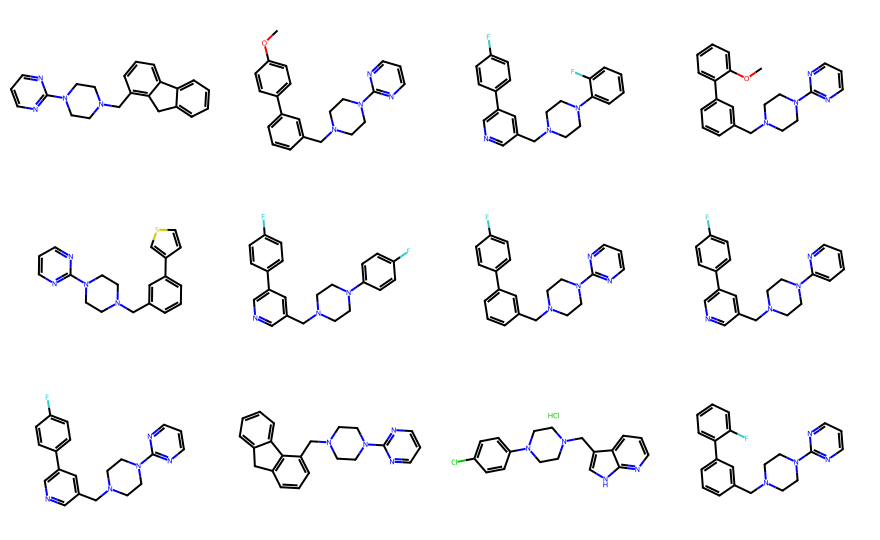

In [19]:
valid_molecules = df_clean["mol"].dropna().head(12).tolist()
display(Draw.MolsToGridImage(
    valid_molecules,
    molsPerRow=4,
    subImgSize=(220, 180),
))

In [20]:
def standardize_mol(mol):
    """Apply a conservative, reproducible RDKit standardization."""
    if mol is None:
        return None
    try:
        fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        largest = max(fragments, key=Chem.Mol.GetNumHeavyAtoms)
        normalized = rdMolStandardize.Normalize(largest)
        reionized = rdMolStandardize.Reionize(normalized)
        uncharged = rdMolStandardize.Uncharger().uncharge(reionized)
        Chem.SanitizeMol(uncharged)
        return uncharged
    except Exception:
        return None


In [21]:
df_clean["mol"] = df_clean["mol"].map(standardize_mol)
df_clean = df_clean[df_clean["mol"].notna()].copy()
df_clean["canonical_smiles_rdkit"] = df_clean["mol"].map(Chem.MolToSmiles)

print("Valid standardized structures:", len(df_clean))


Valid standardized structures: 1097


In [22]:
aggregated = (
    df_clean.groupby("canonical_smiles_rdkit", as_index=False)
    .agg(
        pIC50=("pIC50", "median"),
        n_measurements=("pIC50", "size"),
        pIC50_sd=("pIC50", "std"),
        molecule_chembl_id=("molecule_chembl_id", "first"),
        molecule_name=("molecule_name", "first"),
    )
)
aggregated["pIC50_sd"] = aggregated["pIC50_sd"].fillna(0.0)
aggregated["mol"] = aggregated["canonical_smiles_rdkit"].map(Chem.MolFromSmiles)
aggregated = aggregated[aggregated["mol"].notna()].reset_index(drop=True)

print("Unique standardized molecules:", len(aggregated))
display(aggregated.head())


Unique standardized molecules: 884


,canonical_smiles_rdkit,pIC50,n_measurements,pIC50_sd,molecule_chembl_id,molecule_name,mol
0,C(#Cc1ccccc1)CN(c1ccccc1)C1CCN(Cc2ccccc2)CC1,6.050610,1,0.0,CHEMBL113282,CHEMBL113282,<rdkit.Chem.rdchem.Mol object at 0x12306d1c0>
1,C(=C\c1ccccc1)/CN1CCN(C(c2ccccc2)c2ccccc2)CC1,6.110138,1,0.0,CHEMBL43064,CINNARIZINE,<rdkit.Chem.rdchem.Mol object at 0x12306cdd0>
2,C=C1CCC[C@]2(C)Cc3occ(C)c3C[C@@H]12,5.602060,1,0.0,CHEMBL486189,ATRACTYLON,<rdkit.Chem.rdchem.Mol object at 0x12306d2a0>
3,C=CCN1CCC[C@H]1CNC(=O)c1cc(CCCCl)cc(OC)c1OC,7.767004,1,0.0,CHEMBL502017,CHEMBL502017,<rdkit.Chem.rdchem.Mol object at 0x12306d230>
4,C=CCN1CCC[C@H]1CNC(=O)c1cc(CCCF)cc(OC)c1OC,8.301030,1,0.0,CHEMBL392158,FALLYPRIDE,<rdkit.Chem.rdchem.Mol object at 0x12306d150>


In [23]:
display(
    aggregated["n_measurements"]
    .value_counts()
    .sort_index()
    .head(10)
    .rename("molecules")
    .to_frame()
)


,molecules
n_measurements,
1,739
2,120
3,10
4,7
6,3
7,2
8,1
10,2


In [24]:
repeat_plot = px.histogram(
    aggregated,
    x="n_measurements",
    nbins=max(1, int(aggregated["n_measurements"].max())),
    title="Repeated measurements before aggregation",
    labels={"n_measurements": "Measurements per structure", "count": "Molecules"},
)
repeat_plot.update_layout(bargap=0.15)
repeat_plot.show()


In [25]:
target_plot = px.histogram(
    aggregated,
    x="pIC50",
    nbins=25,
    title="Distribution of aggregated hERG potency",
    labels={"pIC50": "pIC50", "count": "Molecules"},
)
target_plot.show()


In [26]:
from rdkit.Chem import Descriptors

def manual_molecular_weight(mol):
    return sum(atom.GetMass() for atom in mol.GetAtoms())

def manual_atom_count(mol):
    return mol.GetNumAtoms()

def manual_heteroatom_count(mol):
    return sum(atom.GetAtomicNum() not in (1, 6) for atom in mol.GetAtoms())

def manual_aromatic_atom_count(mol):
    return sum(atom.GetIsAromatic() for atom in mol.GetAtoms())


In [27]:
comparison_rows = []
for smiles in ["CCO", "c1ccccc1", "CC(=O)O"]:
    mol = Chem.MolFromSmiles(smiles)
    comparison_rows.append({
        "smiles": smiles,
        "manual_MolWt": manual_molecular_weight(mol),
        "RDKit_MolWt": Descriptors.MolWt(mol),
        "manual_atoms": manual_atom_count(mol),
        "manual_heteroatoms": manual_heteroatom_count(mol),
        "manual_aromatic_atoms": manual_aromatic_atom_count(mol),
    })

manual_comparison = pd.DataFrame(comparison_rows)
display(manual_comparison)
#assert np.allclose(manual_comparison["manual_MolWt"], manual_comparison["RDKit_MolWt"])


,smiles,manual_MolWt,RDKit_MolWt,manual_atoms,manual_heteroatoms,manual_aromatic_atoms
0,CCO,40.021,46.069,3,1,0
1,c1ccccc1,72.066,78.114,6,0,6
2,CC(=O)O,56.020,60.052,4,2,0


In [28]:
from rdkit.Chem import Descriptors, Lipinski

def small_descriptor_vector(mol):
    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotBonds": Lipinski.NumRotatableBonds(mol),
        "RingCount": Lipinski.RingCount(mol),
        "FractionCSP3": Descriptors.FractionCSP3(mol),
    }


In [29]:
X_small = pd.DataFrame(
    [small_descriptor_vector(mol) for mol in aggregated["mol"]]
).replace([np.inf, -np.inf], np.nan)
y = aggregated["pIC50"].to_numpy(dtype=float)

print("Small descriptor matrix:", X_small.shape)
display(X_small.head())


Small descriptor matrix: (884, 8)


,MolWt,LogP,TPSA,HBD,HBA,RotBonds,RingCount,FractionCSP3
0,380.535,5.20930,6.48,0,2,5,4,0.259259
1,368.524,5.10700,6.48,0,2,6,4,0.230769
2,216.324,4.04922,13.14,0,1,0,3,0.600000
3,380.916,3.25540,50.80,1,4,10,2,0.550000
4,364.461,2.98610,50.80,1,4,10,2,0.550000


In [30]:
correlation_plot = px.imshow(
    X_small.corr(),
    zmin=-1,
    zmax=1,
    color_continuous_scale="RdBu_r",
    title="Static descriptor/target correlation",
    aspect="auto",
)
correlation_plot.show()


In [31]:
logp_plot_data = X_small.assign(
    pIC50=y,
    molecule_chembl_id=aggregated["molecule_chembl_id"].to_numpy(),
    molecule_name=aggregated["molecule_name"].to_numpy(),
    canonical_smiles_rdkit=aggregated["canonical_smiles_rdkit"].to_numpy(),
)
logp_plot = px.scatter(
    logp_plot_data,
    x="LogP",
    y="pIC50",
    hover_name="molecule_name",
    hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "pIC50"],
    title="mLogP versus hERG activity",
)
logp_plot.show()


In [32]:
indices = np.arange(len(aggregated))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
)
y = aggregated["pIC50"].to_numpy(dtype=float)

print(f"Random split: {len(train_idx)} train / {len(test_idx)} test")

Random split: 707 train / 177 test


In [33]:
split_summary = pd.DataFrame({
    "split": ["train", "test"],
    "n": [len(train_idx), len(test_idx)],
    "mean_pIC50": [y[train_idx].mean(), y[test_idx].mean()],
    "sd_pIC50": [y[train_idx].std(), y[test_idx].std()],
})
display(split_summary)


,split,n,mean_pIC50,sd_pIC50
0,train,707,6.788658,1.273351
1,test,177,6.839299,1.366553


In [34]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Spearman": pd.Series(y_true).corr(pd.Series(y_pred), method="spearman"),
    }

def fit_evaluate_model(model, X, train_indices, test_indices, representation, split_name="random"):
    X_train = X.iloc[train_indices] if isinstance(X, pd.DataFrame) else X[train_indices]
    X_test = X.iloc[test_indices] if isinstance(X, pd.DataFrame) else X[test_indices]
    y_train, y_test = y[train_indices], y[test_indices]
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    metrics = regression_metrics(y_test, predictions)
    metrics.update({"Representation": representation, "Model": type(model).__name__, "Split": split_name})
    return model, predictions, metrics


In [35]:
results = []
fitted_models = {}

small_models = {
    "small_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "small_RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),
    "small_XGB": XGBRegressor(
      n_estimators=300,
      max_depth=4,
      learning_rate=0.05,
      subsample=0.8,
      colsample_bytree=0.8,
      objective="reg:squarederror",
      random_state=SEED,
      n_jobs=2
    ),
}

In [36]:
for name, model in small_models.items():
    fitted, predictions, metrics = fit_evaluate_model(
        model,
        X_small,
        train_idx,
        test_idx,
        "small descriptors",
    )
    fitted_models[name] = (fitted, predictions)
    results.append(metrics)

random_results = pd.DataFrame(results)
display(random_results.sort_values("RMSE"))


,RMSE,MAE,R2,Spearman,Representation,Model,Split
1,1.149778,0.761122,0.292095,0.665598,small descriptors,Pipeline,random
2,1.181815,0.764904,0.252095,0.679005,small descriptors,XGBRegressor,random
0,1.337100,1.005580,0.042641,0.241544,small descriptors,Pipeline,random


In [37]:
from sklearn.model_selection import KFold, RandomizedSearchCV

tuning_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_searches = {
    "tuned_RF": RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    ),
}

if HAS_XGB:
    tuning_searches["tuned_XGB"] = RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2,
            )),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [2, 3, 5],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 6],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    )
print("Searches:", list(tuning_searches))


Searches: ['tuned_RF', 'tuned_XGB']


In [38]:
tuned_results = []
tuning_cv_tables = {}
for name, search in tuning_searches.items():
    search.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = search.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors, tuned",
        "Model": name,
        "Split": "random",
    })
    tuned_results.append(metrics)
    fitted_models[name] = (search.best_estimator_, predictions)
    tuning_cv_tables[name] = pd.DataFrame(search.cv_results_)
    print(name, "best parameters:", search.best_params_)

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.sort_values("RMSE"))
results.extend(tuned_results)


tuned_RF best parameters: {'model__n_estimators': 400, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
tuned_XGB best parameters: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 6, 'model__max_depth': 5, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.7}


,RMSE,MAE,R2,Spearman,Representation,Model,Split
0,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
1,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random


In [39]:
for name, cv_table in tuning_cv_tables.items():
    search_plot = px.scatter(
        cv_table,
        x="param_model__n_estimators",
        y=-cv_table["mean_test_score"],
        color="rank_test_score",
        hover_data=["params", "std_test_score"],
        title=f"Cross-validation search: {name}",
        labels={"y": "CV RMSE", "param_model__n_estimators": "Number of trees"},
    )
    search_plot.show()


In [40]:
from sklearn.model_selection import KFold, RandomizedSearchCV

tuning_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_searches = {
    "tuned_RF": RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    ),
}

if HAS_XGB:
    tuning_searches["tuned_XGB"] = RandomizedSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                objective="reg:squarederror",
                random_state=SEED,
                n_jobs=2,
            )),
        ]),
        param_distributions={
            "model__n_estimators": [200, 400, 700],
            "model__max_depth": [2, 3, 5],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 6],
        },
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=tuning_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
    )
print("Searches:", list(tuning_searches))


Searches: ['tuned_RF', 'tuned_XGB']


In [41]:
tuned_results = []
tuning_cv_tables = {}
for name, search in tuning_searches.items():
    search.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = search.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors, tuned",
        "Model": name,
        "Split": "random",
    })
    tuned_results.append(metrics)
    fitted_models[name] = (search.best_estimator_, predictions)
    tuning_cv_tables[name] = pd.DataFrame(search.cv_results_)
    print(name, "best parameters:", search.best_params_)

tuned_results_df = pd.DataFrame(tuned_results)
display(tuned_results_df.sort_values("RMSE"))
results.extend(tuned_results)


tuned_RF best parameters: {'model__n_estimators': 400, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
tuned_XGB best parameters: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 6, 'model__max_depth': 5, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.7}


,RMSE,MAE,R2,Spearman,Representation,Model,Split
0,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
1,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random


In [42]:
for name, cv_table in tuning_cv_tables.items():
    search_plot = px.scatter(
        cv_table,
        x="param_model__n_estimators",
        y=-cv_table["mean_test_score"],
        color="rank_test_score",
        hover_data=["params", "std_test_score"],
        title=f"Cross-validation search: {name}",
        labels={"y": "CV RMSE", "param_model__n_estimators": "Number of trees"},
    )
    search_plot.show()


In [43]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer

transformed_models = {
    "scaled_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "scaled_PCA_Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, whiten=True, random_state=SEED)),
        ("model", Ridge(alpha=1.0)),
    ]),
    "scaled_PCA_RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=SEED)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=SEED,
            n_jobs=-1,
        )),
    ]),
}
transformed_results = []
for name, model in transformed_models.items():
    model.fit(X_small.iloc[train_idx], y[train_idx])
    predictions = model.predict(X_small.iloc[test_idx])
    metrics = regression_metrics(y[test_idx], predictions)
    metrics.update({
        "Representation": "small descriptors with transformations",
        "Model": name,
        "Split": "random",
    })
    transformed_results.append(metrics)
transformed_results_df = pd.DataFrame(transformed_results)
display(transformed_results_df.sort_values("RMSE"))
results.extend(transformed_results)


,RMSE,MAE,R2,Spearman,Representation,Model,Split
2,1.112663,0.748677,0.337060,0.642741,small descriptors with transformations,scaled_PCA_RF,random
0,1.332113,0.995931,0.049769,0.280524,small descriptors with transformations,scaled_Ridge,random
1,1.337864,1.010790,0.041546,0.197404,small descriptors with transformations,scaled_PCA_Ridge,random


In [44]:
descriptor_functions = Descriptors.descList

def all_rdkit_descriptors(mol):
    values = {}
    for name, function in descriptor_functions:
        try:
            values[name] = float(function(mol))
        except Exception:
            values[name] = np.nan
    return values


In [45]:
X_rdkit = pd.DataFrame([all_rdkit_descriptors(mol) for mol in aggregated["mol"]])
X_rdkit = X_rdkit.replace([np.inf, -np.inf], np.nan)
print("full RDKit descriptor matrix:", X_rdkit.shape)
print("columns with missing values:", int(X_rdkit.isna().any().sum()))


full RDKit descriptor matrix: (884, 217)
columns with missing values: 0


In [46]:
def filter_descriptor_features(X_train, X_test, correlation_threshold=0.95):
    train = X_train.copy().replace([np.inf, -np.inf], np.nan)
    test = X_test.copy().replace([np.inf, -np.inf], np.nan)
    valid_columns = train.columns[train.notna().any(axis=0)]
    train, test = train[valid_columns], test[valid_columns]

    imputer = SimpleImputer(strategy="median")
    train_imputed = pd.DataFrame(imputer.fit_transform(train), columns=train.columns, index=train.index)
    test_imputed = pd.DataFrame(imputer.transform(test), columns=train.columns, index=test.index)

    variance_filter = VarianceThreshold(threshold=0.0)
    train_var = variance_filter.fit_transform(train_imputed)
    test_var = variance_filter.transform(test_imputed)
    kept_columns = train_imputed.columns[variance_filter.get_support()]
    train_var = pd.DataFrame(train_var, columns=kept_columns, index=train.index)
    test_var = pd.DataFrame(test_var, columns=kept_columns, index=test.index)

    correlation = train_var.corr().abs()
    upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    dropped = [column for column in upper.columns if (upper[column] > correlation_threshold).any()]
    kept = [column for column in train_var.columns if column not in dropped]
    return train_var[kept], test_var[kept], kept


In [47]:
X_rdkit_train, X_rdkit_test, rdkit_feature_names = filter_descriptor_features(
    X_rdkit.iloc[train_idx], X_rdkit.iloc[test_idx]
)
print(f"filtered RDKit features: {len(rdkit_feature_names)}")



filtered RDKit features: 155


In [48]:
rdkit_model = RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1)
rdkit_model.fit(X_rdkit_train, y[train_idx])
rdkit_predictions = rdkit_model.predict(X_rdkit_test)
rdkit_metrics = regression_metrics(y[test_idx], rdkit_predictions)
rdkit_metrics.update({"Representation": "full RDKit descriptors", "Model": "RandomForestRegressor", "Split": "random"})
results.append(rdkit_metrics)
fitted_models["rdkit_RF"] = (rdkit_model, rdkit_predictions)
print(rdkit_metrics)


{'RMSE': 1.0798232029970314, 'MAE': 0.6608633173655817, 'R2': 0.37561514389953643, 'Spearman': np.float64(0.7301772625691757), 'Representation': 'full RDKit descriptors', 'Model': 'RandomForestRegressor', 'Split': 'random'}


In [49]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

MORGAN_SIZE = 2048
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=MORGAN_SIZE)


In [50]:
def morgan_array(mol):
    fingerprint = morgan_generator.GetFingerprint(mol)
    array = np.zeros((MORGAN_SIZE,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fingerprint, array)
    return array


In [51]:
X_morgan = np.vstack([morgan_array(mol) for mol in aggregated["mol"]])
print("Morgan matrix:", X_morgan.shape)


Morgan matrix: (884, 2048)


In [52]:
morgan_model = RandomForestRegressor(
    n_estimators=500,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1,
)


In [53]:
morgan_model.fit(X_morgan[train_idx], y[train_idx])
morgan_predictions = morgan_model.predict(X_morgan[test_idx])
morgan_metrics = regression_metrics(y[test_idx], morgan_predictions)
morgan_metrics.update({"Representation": "Morgan fingerprints", "Model": "RandomForestRegressor", "Split": "random"})
results.append(morgan_metrics)
fitted_models["morgan_RF"] = (morgan_model, morgan_predictions)
print(morgan_metrics)


{'RMSE': 0.9985822266408513, 'MAE': 0.5968773795329527, 'R2': 0.4660326351876458, 'Spearman': np.float64(0.7942503742905583), 'Representation': 'Morgan fingerprints', 'Model': 'RandomForestRegressor', 'Split': 'random'}


In [54]:
def tanimoto_similarity(mol_a, mol_b):
    fp_a = morgan_generator.GetFingerprint(mol_a)
    fp_b = morgan_generator.GetFingerprint(mol_b)
    return DataStructs.TanimotoSimilarity(fp_a, fp_b)


In [55]:
test_position = int(test_idx[0])
test_mol = aggregated.loc[test_position, "mol"]
neighbour_rows = []
for train_position in train_idx:
    train_mol = aggregated.loc[int(train_position), "mol"]
    neighbour_rows.append({
        "train_index": int(train_position),
        "smiles": aggregated.loc[int(train_position), "canonical_smiles_rdkit"],
        "pIC50": y[int(train_position)],
        "Tanimoto": tanimoto_similarity(test_mol, train_mol),
    })
nearest_neighbours = pd.DataFrame(neighbour_rows).sort_values("Tanimoto", ascending=False).head(5)
print("test molecule:", aggregated.loc[test_position, "canonical_smiles_rdkit"])
display(nearest_neighbours)


test molecule: CC(CNCc1ccc(CCNC[C@H](O)c2ccc(O)c3[nH]c(=O)sc23)cc1)c1ccccc1


,train_index,smiles,pIC50,Tanimoto
289,803,O=c1[nH]c2c(O)ccc([C@@H](O)CNCCc3ccc(CNCCc4ccc...,5.700001,0.813559
482,804,O=c1[nH]c2c(O)ccc([C@@H](O)CNCCc3ccc(CNCCc4ccc...,5.700001,0.701493
0,404,COc1ccccc1CNCc1ccc(CCNC[C@@H](O)c2ccc(O)c3[nH]...,5.700001,0.695652
219,405,COc1ccccc1CNCc1ccc(CCNC[C@H](O)c2ccc(O)c3[nH]c...,5.599999,0.695652
622,401,COc1ccccc1CCNCc1ccc(CCNC[C@H](O)c2ccc(O)c3[nH]...,6.199998,0.695652


In [56]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.warning")  # the Python path is chatty about hydrogens

def murcko_scaffold_smiles(mol):
    """Bemis-Murcko scaffold as canonical SMILES.

    rdkit 2026.09.2's C++ Chem.MurckoDecompose raises RuntimeError("bad any cast")
    for every molecule, so fall back to the pure-Python implementation.
    """
    if mol is None:
        return None
    if mol.GetRingInfo().NumRings() == 0:
        return ""                      # acyclic -> no ring system -> no scaffold
    try:
        scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    except Exception:
        try:
            scaffold = MurckoScaffold._pyGetScaffoldForMol(mol)
        except Exception:
            # keep the molecule as its own scaffold group instead of losing it
            return Chem.MolToSmiles(mol, canonical=True)
    if scaffold is None or scaffold.GetNumAtoms() == 0:
        return ""
    return Chem.MolToSmiles(scaffold, canonical=True)


In [57]:
aggregated["scaffold"] = aggregated["mol"].map(murcko_scaffold_smiles)
print("unique scaffolds:", aggregated["scaffold"].nunique())
display(aggregated[["canonical_smiles_rdkit", "scaffold"]].head())


[23:30:34] Can't kekulize mol.  Unkekulized atoms: 7 8 9 10 11 12 13 14 15 16 17 18 19
[23:30:34] Can't kekulize mol.  Unkekulized atoms: 7 8 9 10 11 12 13 14 15 16 17 18 19
[23:30:34] Can't kekulize mol.  Unkekulized atoms: 0 1 2 22 23 24 25 26 27
[23:30:34] Can't kekulize mol.  Unkekulized atoms: 0 1 2 22 23 24 25 26 27


unique scaffolds: 470


,canonical_smiles_rdkit,scaffold
0,C(#Cc1ccccc1)CN(c1ccccc1)C1CCN(Cc2ccccc2)CC1,C(#Cc1ccccc1)CN(c1ccccc1)C1CCN(Cc2ccccc2)CC1
1,C(=C\c1ccccc1)/CN1CCN(C(c2ccccc2)c2ccccc2)CC1,C(=C\c1ccccc1)/CN1CCN(C(c2ccccc2)c2ccccc2)CC1
2,C=C1CCC[C@]2(C)Cc3occ(C)c3C[C@@H]12,C=C1CCC[C@@H]2Cc3occc3C[C@@H]12
3,C=CCN1CCC[C@H]1CNC(=O)c1cc(CCCCl)cc(OC)c1OC,O=C(NC[C@@H]1CCCN1)c1ccccc1
4,C=CCN1CCC[C@H]1CNC(=O)c1cc(CCCF)cc(OC)c1OC,O=C(NC[C@@H]1CCCN1)c1ccccc1


In [58]:
def scaffold_split(df, scaffold_col="scaffold", train_frac=0.8, val_frac=0.1):
    groups = [group.index.to_list() for _, group in df.groupby(scaffold_col)]
    groups = sorted(groups, key=len, reverse=True)
    n_total = len(df)
    n_train = int(train_frac * n_total)
    n_val = int(val_frac * n_total)
    train_ids, val_ids, test_ids = [], [], []
    for group in groups:
        if len(train_ids) + len(group) <= n_train:
            train_ids.extend(group)
        elif len(val_ids) + len(group) <= n_val:
            val_ids.extend(group)
        else:
            test_ids.extend(group)
    return np.array(train_ids, dtype=int), np.array(val_ids, dtype=int), np.array(test_ids, dtype=int)


In [59]:
scaffold_train_idx, scaffold_val_idx, scaffold_test_idx = scaffold_split(aggregated)
train_scaffolds = set(aggregated.loc[scaffold_train_idx, "scaffold"])
test_scaffolds = set(aggregated.loc[scaffold_test_idx, "scaffold"])
print("scaffold split:", len(scaffold_train_idx), len(scaffold_val_idx), len(scaffold_test_idx))
print("overlap:", len(train_scaffolds & test_scaffolds))
assert train_scaffolds.isdisjoint(test_scaffolds)

scaffold split: 707 88 89
overlap: 0


In [60]:
scaffold_models = {
    "small descriptors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ]),
    "Morgan fingerprints": RandomForestRegressor(
        n_estimators=500, max_features="sqrt", random_state=SEED, n_jobs=-1
    ),
}


In [61]:
for representation, model in scaffold_models.items():
    X_representation = X_small if representation == "small descriptors" else X_morgan
    X_train = X_representation.iloc[scaffold_train_idx] if isinstance(X_representation, pd.DataFrame) else X_representation[scaffold_train_idx]
    X_test = X_representation.iloc[scaffold_test_idx] if isinstance(X_representation, pd.DataFrame) else X_representation[scaffold_test_idx]
    model.fit(X_train, y[scaffold_train_idx])
    predictions = model.predict(X_test)
    metrics = regression_metrics(y[scaffold_test_idx], predictions)
    metrics.update({"Representation": representation, "Model": type(model).__name__, "Split": "scaffold"})
    results.append(metrics)


In [62]:
results_so_far = pd.DataFrame(results)
display(results_so_far.sort_values(["Split", "RMSE"]))


,RMSE,MAE,R2,Spearman,Representation,Model,Split
11,0.998582,0.596877,0.466033,0.794250,Morgan fingerprints,RandomForestRegressor,random
10,1.079823,0.660863,0.375615,0.730177,full RDKit descriptors,RandomForestRegressor,random
9,1.112663,0.748677,0.337060,0.642741,small descriptors with transformations,scaled_PCA_RF,random
3,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
5,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
4,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random
6,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random
1,1.149778,0.761122,0.292095,0.665598,small descriptors,Pipeline,random
2,1.181815,0.764904,0.252095,0.679005,small descriptors,XGBRegressor,random
7,1.332113,0.995931,0.049769,0.280524,small descriptors with transformations,scaled_Ridge,random


In [63]:
def nearest_train_similarity(test_mol, train_mols):
    fp_test = morgan_generator.GetFingerprint(test_mol)
    similarities = [
        DataStructs.TanimotoSimilarity(fp_test, morgan_generator.GetFingerprint(mol))
        for mol in train_mols
    ]
    return max(similarities) if similarities else np.nan


In [64]:
train_mols = aggregated.loc[train_idx, "mol"].tolist()
small_test_predictions = fitted_models["small_RF"][1]
applicability = pd.DataFrame({
    "nearest_train_similarity": [
        nearest_train_similarity(aggregated.loc[index, "mol"], train_mols)
        for index in test_idx
    ],
    "absolute_error": np.abs(y[test_idx] - small_test_predictions),
})
display(applicability.describe())


,nearest_train_similarity,absolute_error
count,177.000000,177.000000
mean,0.755272,0.761122
std,0.153774,0.864234
min,0.192661,0.001772
25%,0.718750,0.346372
50%,0.775862,0.608194
75%,0.833333,1.048671
max,1.000000,10.035228


In [65]:
applicability_plot_data = applicability.copy()
applicability_plot_data["molecule_chembl_id"] = aggregated.loc[
    test_idx, "molecule_chembl_id"
].to_numpy()
applicability_plot_data["molecule_name"] = aggregated.loc[
    test_idx, "molecule_name"
].to_numpy()
applicability_plot_data["canonical_smiles_rdkit"] = aggregated.loc[
    test_idx, "canonical_smiles_rdkit"
].to_numpy()
applicability_plot = px.scatter(
    applicability_plot_data,
    x="nearest_train_similarity",
    y="absolute_error",
    hover_name="molecule_name",
    hover_data=["molecule_chembl_id", "canonical_smiles_rdkit", "absolute_error"],
    title="Applicability-domain diagnostic",
)
applicability_plot.show()


In [66]:
from rdkit.Chem import AllChem, Descriptors3D

def generate_3d_mol(mol, seed=42):
    embedded = Chem.AddHs(Chem.Mol(mol))
    params = AllChem.ETKDGv3()
    params.randomSeed = seed
    if AllChem.EmbedMolecule(embedded, params) != 0:
        return None
    try:
        AllChem.MMFFOptimizeMolecule(embedded)
    except Exception:
        try:
            AllChem.UFFOptimizeMolecule(embedded)
        except Exception:
            pass
    return embedded


In [67]:
def descriptors_3d(mol_3d):
    return {
        "RadiusOfGyration": Descriptors3D.RadiusOfGyration(mol_3d),
        "Asphericity": Descriptors3D.Asphericity(mol_3d),
        "Eccentricity": Descriptors3D.Eccentricity(mol_3d),
        "PMI1": Descriptors3D.PMI1(mol_3d),
        "PMI2": Descriptors3D.PMI2(mol_3d),
        "PMI3": Descriptors3D.PMI3(mol_3d),
        "SpherocityIndex": Descriptors3D.SpherocityIndex(mol_3d),
    }


In [68]:
n_3d = min(100, len(aggregated))
descriptor_3d_rows = []
for index, mol in aggregated["mol"].iloc[:n_3d].items():
    mol_3d = generate_3d_mol(mol, seed=SEED + int(index))
    if mol_3d is not None:
        descriptor_3d_rows.append({"index": index, **descriptors_3d(mol_3d)})
descriptors_3d_df = pd.DataFrame(descriptor_3d_rows).set_index("index")
display(descriptors_3d_df.head())
print("successfully embedded:", len(descriptors_3d_df), "of", n_3d)


,RadiusOfGyration,Asphericity,Eccentricity,PMI1,PMI2,PMI3,SpherocityIndex
index,,,,,,,
0,4.834137,0.369038,0.957218,2461.298651,6818.263703,8505.793949,0.206723
1,5.034145,0.564304,0.984476,1573.030304,8143.450356,8962.245276,0.204773
2,2.845370,0.359694,0.955256,493.976638,1338.712324,1670.086784,0.258309
3,4.244622,0.378118,0.959047,1794.411850,5596.199179,6335.176830,0.225253
4,4.636833,0.466637,0.973794,1715.196188,6415.202118,7541.586700,0.143294


successfully embedded: 100 of 100


In [69]:
try:
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader
    from torch_geometric.nn import GINEConv, global_add_pool, global_mean_pool, global_max_pool
    HAS_PYG = True
except ImportError as exc:
    HAS_PYG = False
    print("PyTorch Geometric is not available; GNN cells will be skipped.")
    print(exc)


/Users/alegator1209/Documents/KSE/term-4/ml/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [70]:
if HAS_PYG:
    NODE_FEATURE_DIM = 15
    EDGE_FEATURE_DIM = 10

    def molecule_to_pyg_data(mol, target):
        """Convert RDKit atoms and bonds into an edge-aware graph."""
        atom_features = []
        for atom in mol.GetAtoms():
            hybridization = atom.GetHybridization()
            atom_features.append([
                atom.GetAtomicNum() / 100.0,
                atom.GetDegree() / 5.0,
                atom.GetFormalCharge() / 3.0,
                atom.GetTotalNumHs() / 8.0,
                atom.GetTotalValence() / 8.0,
                atom.GetMass() / 200.0,
                float(atom.GetIsAromatic()),
                float(atom.IsInRing()),
                float(hybridization == Chem.HybridizationType.SP),
                float(hybridization == Chem.HybridizationType.SP2),
                float(hybridization == Chem.HybridizationType.SP3),
                float(atom.GetChiralTag() != Chem.ChiralType.CHI_UNSPECIFIED),
                float(atom.GetNoImplicit()),
                float(atom.GetNumRadicalElectrons() > 0),
                float(atom.GetIsotope() > 0),
            ])

        bond_types = [
            Chem.BondType.SINGLE,
            Chem.BondType.DOUBLE,
            Chem.BondType.TRIPLE,
            Chem.BondType.AROMATIC,
        ]
        stereo_types = [
            Chem.BondStereo.STEREONONE,
            Chem.BondStereo.STEREOANY,
            Chem.BondStereo.STEREOZ,
            Chem.BondStereo.STEREOE,
        ]
        edge_pairs, edge_features = [], []
        for bond in mol.GetBonds():
            begin = bond.GetBeginAtomIdx()
            end = bond.GetEndAtomIdx()
            bond_feature = [
                float(bond.GetBondType() == bond_type)
                for bond_type in bond_types
            ] + [
                float(bond.GetIsConjugated()),
                float(bond.IsInRing()),
            ] + [
                float(bond.GetStereo() == stereo)
                for stereo in stereo_types
            ]
            for source_index, destination_index in [(begin, end), (end, begin)]:
                edge_pairs.append([source_index, destination_index])
                edge_features.append(bond_feature)

        edge_index = torch.tensor(
            edge_pairs,
            dtype=torch.long,
        ).t().contiguous()
        edge_attr = torch.tensor(
            edge_features,
            dtype=torch.float32,
        ).reshape(-1, EDGE_FEATURE_DIM)
        return Data(
            x=torch.tensor(atom_features, dtype=torch.float32),
            edge_index=edge_index,
            edge_attr=edge_attr,
            y=torch.tensor([target], dtype=torch.float32),
        )


In [71]:
if HAS_PYG:
    class DeepGINERegressor(nn.Module):
        def __init__(self, in_dim, edge_dim, hidden_dim=128, num_layers=5, dropout=0.15):
            super().__init__()
            self.input_projection = nn.Linear(in_dim, hidden_dim)
            self.convs = nn.ModuleList()
            self.norms = nn.ModuleList()
            for _ in range(num_layers):
                mlp = nn.Sequential(
                    nn.Linear(hidden_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, hidden_dim),
                )
                self.convs.append(
                    GINEConv(mlp, edge_dim=edge_dim, train_eps=True)
                )
                self.norms.append(nn.BatchNorm1d(hidden_dim))
            self.dropout = nn.Dropout(dropout)
            self.head = nn.Sequential(
                nn.Linear(3 * hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, 1),
            )

        def forward(self, x, edge_index, edge_attr, batch):
            x = F.relu(self.input_projection(x))
            for convolution, normalization in zip(self.convs, self.norms):
                residual = x
                x = convolution(x, edge_index, edge_attr)
                x = normalization(x)
                x = F.relu(x)
                x = self.dropout(x)
                x = x + residual
            pooled = torch.cat([
                global_mean_pool(x, batch),
                global_max_pool(x, batch),
                global_add_pool(x, batch),
            ], dim=1)
            return self.head(pooled).squeeze(-1)

    # Keep old names available for downstream teaching cells.
    DeepGINRegressor = DeepGINERegressor
    GINRegressor = DeepGINERegressor


In [72]:
graph_dataset = [molecule_to_pyg_data(mol, target_value) for mol, target_value in zip(aggregated["mol"], y)]
graph_train = [graph_dataset[index] for index in train_idx]
graph_test = [graph_dataset[index] for index in test_idx]
train_loader = DataLoader(graph_train, batch_size=32, shuffle=True)
test_loader = DataLoader(graph_test, batch_size=64, shuffle=False)


In [73]:
if HAS_PYG:
    graph_model = DeepGINERegressor(
        in_dim=graph_dataset[0].x.shape[1],
        edge_dim=graph_dataset[0].edge_attr.shape[1],
        hidden_dim=128,
        num_layers=5,
        dropout=0.15,
    )
    optimizer = torch.optim.Adam(
        graph_model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )
    loss_function = nn.MSELoss()


In [74]:
torch.set_num_threads(1)

graph_model.train()
for epoch in range(50):
        print(f"Epoch {epoch}")
        for batch in train_loader:
            optimizer.zero_grad()
            prediction = graph_model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            loss = loss_function(prediction, batch.y.view(-1))
            loss.backward()
            optimizer.step()
print(f"Final training loss: {loss.item():.4f}")


Epoch 0
Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10
Epoch 11
Epoch 12
Epoch 13
Epoch 14
Epoch 15
Epoch 16
Epoch 17
Epoch 18
Epoch 19
Epoch 20
Epoch 21
Epoch 22
Epoch 23
Epoch 24
Epoch 25
Epoch 26
Epoch 27
Epoch 28
Epoch 29
Epoch 30
Epoch 31
Epoch 32
Epoch 33
Epoch 34
Epoch 35
Epoch 36
Epoch 37
Epoch 38
Epoch 39
Epoch 40
Epoch 41
Epoch 42
Epoch 43
Epoch 44
Epoch 45
Epoch 46
Epoch 47
Epoch 48
Epoch 49
Final training loss: 1.3202


In [75]:

graph_model.eval()
with torch.no_grad():
        graph_predictions = np.concatenate([
            graph_model(batch.x, batch.edge_index, batch.edge_attr, batch.batch).cpu().numpy()
            for batch in test_loader
        ])
graph_metrics = regression_metrics(y[test_idx], graph_predictions)
graph_metrics.update({
        "Representation": "molecular graph",
        "Model": "DeepGINERegressor",
        "Split": "random",
    })

results.append(graph_metrics)
print(graph_metrics)


{'RMSE': 1.8925472605428535, 'MAE': 1.5742100696946189, 'R2': -0.9179642927230427, 'Spearman': np.float64(0.7325426384866276), 'Representation': 'molecular graph', 'Model': 'DeepGINERegressor', 'Split': 'random'}


,RMSE,MAE,R2,Spearman,Representation,Model,Split
0,0.998582,0.596877,0.466033,0.794250,Morgan fingerprints,RandomForestRegressor,random
1,1.079823,0.660863,0.375615,0.730177,full RDKit descriptors,RandomForestRegressor,random
2,1.112663,0.748677,0.337060,0.642741,small descriptors with transformations,scaled_PCA_RF,random
3,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
4,1.133867,0.738350,0.311552,0.693235,"small descriptors, tuned",tuned_RF,random
5,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random
6,1.147736,0.758143,0.294608,0.685223,"small descriptors, tuned",tuned_XGB,random
7,1.149778,0.761122,0.292095,0.665598,small descriptors,Pipeline,random
8,1.181815,0.764904,0.252095,0.679005,small descriptors,XGBRegressor,random
9,1.332113,0.995931,0.049769,0.280524,small descriptors with transformations,scaled_Ridge,random


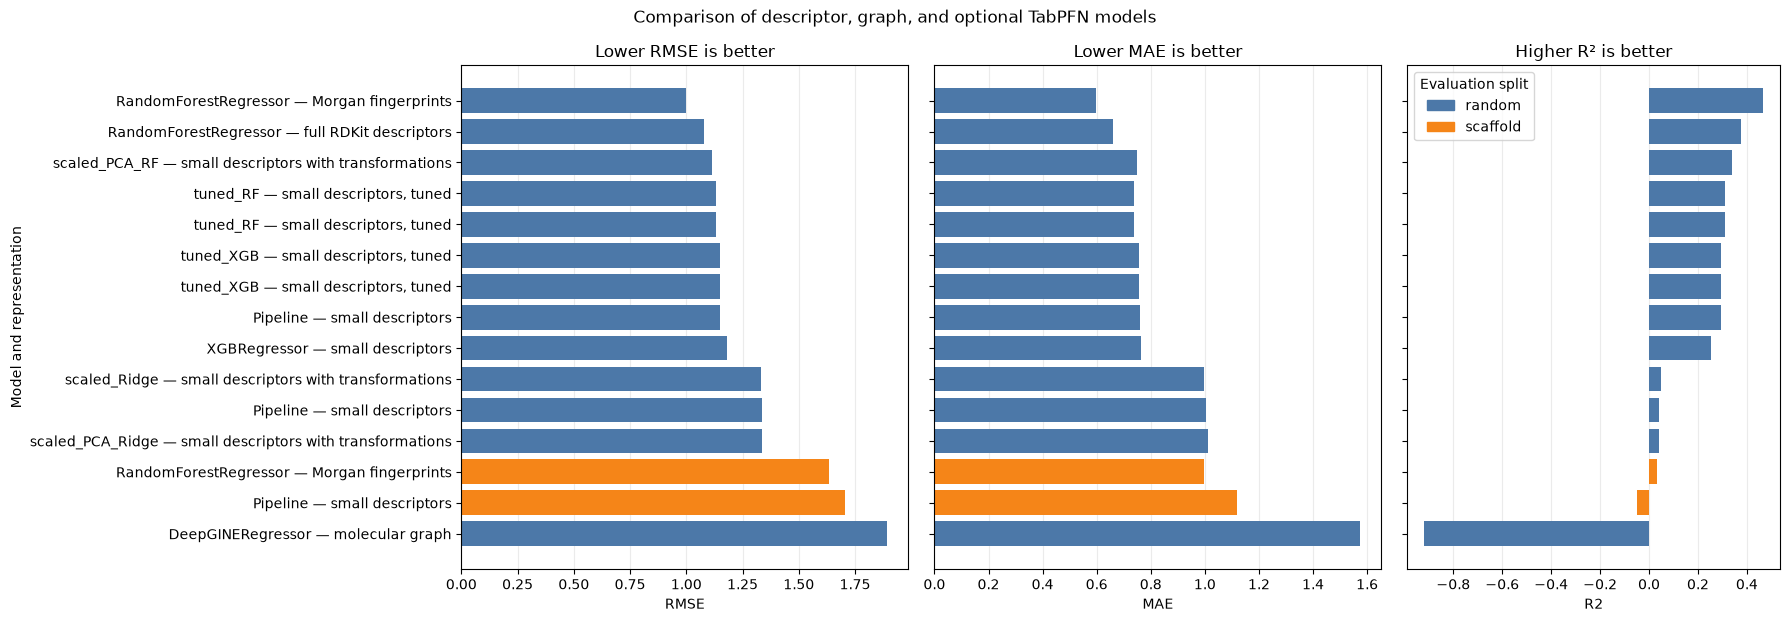

In [76]:
results_df = pd.DataFrame(results).copy()
results_df = results_df.dropna(subset=["RMSE"]).reset_index(drop=True)
display(results_df.sort_values(["Split", "RMSE"]).reset_index(drop=True))

# Static plots make it easier to compare all fitted models at once and
# remain readable when the notebook is exported to HTML or PDF.
plot_results = results_df.sort_values("RMSE", ascending=True).reset_index(drop=True)
plot_results["label"] = plot_results.apply(
    lambda row: f"{row['Model']} — {row['Representation']}",
    axis=1,
)
split_colors = {
    "random": "#4C78A8",
    "scaffold": "#F58518",
}
colors = plot_results["Split"].map(split_colors).fillna("#B279A2")
y_positions = np.arange(len(plot_results))
figure_height = max(6, 0.42 * len(plot_results))
figure, axes = plt.subplots(
    1,
    3,
    figsize=(18, figure_height),
    sharey=True,
    gridspec_kw={"width_ratios": [1.2, 1.2, 1.0]},
)

for axis, metric, title in zip(
    axes,
    ["RMSE", "MAE", "R2"],
    ["Lower RMSE is better", "Lower MAE is better", "Higher R² is better"],
):
    axis.barh(y_positions, plot_results[metric], color=colors)
    axis.set_title(title)
    axis.set_xlabel(metric)
    axis.grid(axis="x", alpha=0.25)
    axis.set_axisbelow(True)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(plot_results["label"])
axes[0].invert_yaxis()
axes[0].set_ylabel("Model and representation")
from matplotlib.patches import Patch
axes[2].legend(
    handles=[Patch(color=color, label=split) for split, color in split_colors.items()],
    title="Evaluation split",
    loc="best",
)
figure.suptitle("Comparison of descriptor, graph, and optional TabPFN models")
figure.tight_layout()
plt.show()


# Homework part

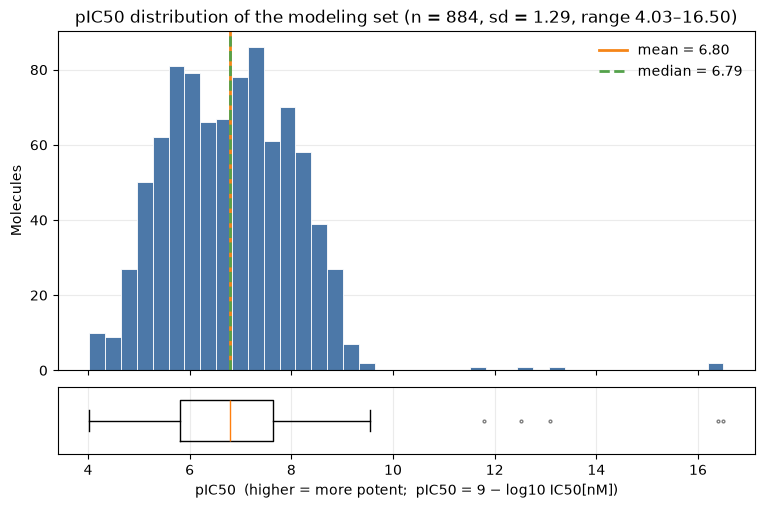

In [77]:
pic50 = aggregated["pIC50"]

figure, (axis_hist, axis_box) = plt.subplots(
    2, 1, figsize=(9, 5.5), sharex=True,
    gridspec_kw={"height_ratios": [5, 1], "hspace": 0.08},
)

axis_hist.hist(pic50, bins=40, color="#4C78A8", edgecolor="white", linewidth=0.6)
axis_hist.axvline(pic50.mean(), color="#F58518", linewidth=2,
                  label=f"mean = {pic50.mean():.2f}")
axis_hist.axvline(pic50.median(), color="#54A24B", linewidth=2, linestyle="--",
                  label=f"median = {pic50.median():.2f}")
axis_hist.set_ylabel("Molecules")
axis_hist.set_title(
    f"pIC50 distribution of the modeling set "
    f"(n = {len(pic50)}, sd = {pic50.std():.2f}, "
    f"range {pic50.min():.2f}–{pic50.max():.2f})"
)
axis_hist.legend(frameon=False)
axis_hist.grid(axis="y", alpha=0.25)
axis_hist.set_axisbelow(True)

axis_box.boxplot(pic50, orientation="horizontal", widths=0.6, showfliers=True,
                 flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
axis_box.set_yticks([])
axis_box.set_xlabel("pIC50  (higher = more potent;  pIC50 = 9 − log10 IC50[nM])")
axis_box.grid(axis="x", alpha=0.25)
axis_box.set_axisbelow(True)

plt.show()

In [ ]:
THRESHOLD = 7.0
CUTOFF_NM = 10 ** (9 - THRESHOLD)

exact_part = aggregated[
    ["canonical_smiles_rdkit", "mol", "molecule_chembl_id", "pIC50", "n_measurements"]
].copy()
exact_part["active"] = (exact_part["pIC50"] >= THRESHOLD).astype(int)
exact_part["label_source"] = "exact"
exact_part["censoring_bound_nM"] = np.nan

censored = df[
    (df["standard_units"] == "nM")
    & (df["standard_value"] > 0)
    & df["canonical_smiles"].notna()
    & (
        ((df["standard_relation"] == ">") & (df["standard_value"] >= CUTOFF_NM))
        | ((df["standard_relation"] == "<") & (df["standard_value"] <= CUTOFF_NM))
    )
].copy()
censored["active"] = (censored["standard_relation"] == "<").astype(int)

censored["mol"] = censored["canonical_smiles"].map(Chem.MolFromSmiles).map(standardize_mol)
censored = censored[censored["mol"].notna()].copy()
censored["canonical_smiles_rdkit"] = censored["mol"].map(Chem.MolToSmiles)

censored_agg = censored.groupby("canonical_smiles_rdkit", as_index=False).agg(
    active=("active", "max"),
    distinct_labels=("active", "nunique"),
    n_censored=("active", "size"),
    molecule_chembl_id=("molecule_chembl_id", "first"),
    censoring_bound_nM=("standard_value", "max"),
)
conflicting = censored_agg[censored_agg["distinct_labels"] > 1]
censored_agg = censored_agg[censored_agg["distinct_labels"] == 1]
already_exact = censored_agg["canonical_smiles_rdkit"].isin(
    exact_part["canonical_smiles_rdkit"]
)
print(f"censored molecules: {len(censored_agg) + len(conflicting)}"
      f" | self-contradictory: {len(conflicting)}"
      f" | already measured exactly: {int(already_exact.sum())}")

censored_part = censored_agg[~already_exact].copy()
censored_part["mol"] = censored_part["canonical_smiles_rdkit"].map(Chem.MolFromSmiles)
censored_part = censored_part[censored_part["mol"].notna()]
censored_part["pIC50"] = np.nan          # no point estimate exists for these
censored_part["n_measurements"] = 0
censored_part["label_source"] = "censored"

columns = ["canonical_smiles_rdkit", "mol", "molecule_chembl_id", "pIC50",
           "n_measurements", "active", "label_source", "censoring_bound_nM"]
classification_df = pd.concat(
    [exact_part[columns], censored_part[columns]], ignore_index=True
)
classification_df["scaffold"] = classification_df["mol"].map(murcko_scaffold_smiles)

assert classification_df["canonical_smiles_rdkit"].is_unique
assert classification_df["active"].isin([0, 1]).all()
assert classification_df["mol"].notna().all()

display(pd.crosstab(classification_df["label_source"], classification_df["active"],
                    margins=True, margins_name="total"))
print(f"molecules: {len(classification_df)} "
      f"(+{100 * len(censored_part) / len(exact_part):.0f}% over the regression set) | "
      f"active fraction: {classification_df['active'].mean():.3f} | "
      f"scaffolds: {classification_df['scaffold'].nunique()}")

censored molecules: 393 | self-contradictory: 0 | already measured exactly: 20


[23:45:24] Can't kekulize mol.  Unkekulized atoms: 7 8 9 10 11 12 13 14 15 16 17 18 19
[23:45:24] Can't kekulize mol.  Unkekulized atoms: 7 8 9 10 11 12 13 14 15 16 17 18 19
[23:45:24] Can't kekulize mol.  Unkekulized atoms: 0 1 2 22 23 24 25 26 27
[23:45:24] Can't kekulize mol.  Unkekulized atoms: 0 1 2 22 23 24 25 26 27


active,0,1,total
label_source,,,
censored,372,1,373
exact,490,394,884
total,862,395,1257


molecules: 1257 (+42% over the regression set) | active fraction: 0.314 | scaffolds: 627


In [87]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

y_class = classification_df["active"].to_numpy()
groups = classification_df["scaffold"].to_numpy()
indices = np.arange(len(classification_df))

cls_train_idx, holdout_idx = train_test_split(
    indices, test_size=0.2, random_state=SEED, stratify=y_class
)
cls_val_idx, cls_test_idx = train_test_split(
    holdout_idx, test_size=0.5, random_state=SEED, stratify=y_class[holdout_idx]
)

splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = [test for _, test in splitter.split(indices, y_class, groups=groups)]
scaffold_cls_test_idx = folds[0]
scaffold_cls_val_idx = folds[1]
scaffold_cls_train_idx = np.concatenate(folds[2:])


def split_report(name, splits):
    rows = [{
        "split": label,
        "n": len(idx),
        "active": int(y_class[idx].sum()),
        "inactive": int((1 - y_class[idx]).sum()),
        "active_frac": round(float(y_class[idx].mean()), 3),
        "scaffolds": len(set(groups[idx])),
        "largest_group": int(pd.Series(groups[idx]).value_counts().iloc[0]),
    } for label, idx in splits.items()]
    print(f"\n{name}")
    display(pd.DataFrame(rows))


split_report("random stratified split", {
    "train": cls_train_idx, "val": cls_val_idx, "test": cls_test_idx})
split_report("scaffold split (StratifiedGroupKFold)", {
    "train": scaffold_cls_train_idx, "val": scaffold_cls_val_idx,
    "test": scaffold_cls_test_idx})
print(f"whole set active fraction: {y_class.mean():.3f}")


random stratified split


,split,n,active,inactive,active_frac,scaffolds,largest_group
0,train,1005,316,689,0.314,524,62
1,val,126,40,86,0.317,106,5
2,test,126,39,87,0.310,94,8



scaffold split (StratifiedGroupKFold)


,split,n,active,inactive,active_frac,scaffolds,largest_group
0,train,1009,319,690,0.316,533,63
1,val,124,38,86,0.306,59,28
2,test,124,38,86,0.306,35,75


whole set active fraction: 0.314


In [88]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, matthews_corrcoef, roc_auc_score)
from xgboost import XGBClassifier

X_small_cls = pd.DataFrame(
    [small_descriptor_vector(mol) for mol in classification_df["mol"]]
).replace([np.inf, -np.inf], np.nan)
X_morgan_cls = np.vstack([morgan_array(mol) for mol in classification_df["mol"]])


def classification_metrics(y_true, y_pred, y_proba):
    return {
        "ROC_AUC": roc_auc_score(y_true, y_proba),
        "PR_AUC": average_precision_score(y_true, y_proba),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "BalAcc": balanced_accuracy_score(y_true, y_pred),
    }


def fit_evaluate_classifier(model, X, train_indices, test_indices,
                            representation, split_name="random"):
    X_train = X.iloc[train_indices] if isinstance(X, pd.DataFrame) else X[train_indices]
    X_test = X.iloc[test_indices] if isinstance(X, pd.DataFrame) else X[test_indices]
    model.fit(X_train, y_class[train_indices])
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    metrics = classification_metrics(y_class[test_indices], predictions, probabilities)
    metrics.update({"Representation": representation,
                    "Model": type(model).__name__, "Split": split_name})
    return model, predictions, metrics


classification_results = []
fitted_classifiers = {}

small_classifiers = {
    "small_RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=8,
        )),
    ]),
    "small_XGB": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=2,
    ),
}

for name, model in small_classifiers.items():
    fitted, predictions, metrics = fit_evaluate_classifier(
        model, X_small_cls, cls_train_idx, cls_test_idx, "small descriptors")
    fitted_classifiers[name] = (fitted, predictions)
    classification_results.append(metrics)

display(pd.DataFrame(classification_results).sort_values("ROC_AUC", ascending=False))

,ROC_AUC,PR_AUC,MCC,BalAcc,Representation,Model,Split
0,0.854701,0.717875,0.50985,0.759947,small descriptors,Pipeline,random
1,0.852933,0.700247,0.52121,0.750221,small descriptors,XGBClassifier,random


In [89]:
from torch_geometric.nn import GCNConv, GINConv, global_mean_pool

torch.manual_seed(SEED)

graph_dataset_cls = [
    molecule_to_pyg_data(mol, float(label))
    for mol, label in zip(classification_df["mol"], y_class)
]

class GraphClassifier(nn.Module):
    def __init__(self, in_dim, edge_dim, conv="GIN", hidden_dim=64,
                 num_layers=3, dropout=0.2):
        super().__init__()
        self.conv_name = conv
        self.input_projection = nn.Linear(in_dim, hidden_dim)
        self.convs = nn.ModuleList()
        for _ in range(num_layers):
            if conv == "GCN":
                layer = GCNConv(hidden_dim, hidden_dim)
            else:
                mlp = nn.Sequential(
                  nn.Linear(hidden_dim, hidden_dim),
                  nn.ReLU(),
                  nn.Linear(hidden_dim, hidden_dim)
                )
                layer = (GINEConv(mlp, edge_dim=edge_dim, train_eps=True)
                         if conv == "GINE" else GINConv(mlp, train_eps=True))
            self.convs.append(layer)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.input_projection(x))
        for conv in self.convs:
            x = conv(x, edge_index, edge_attr) if self.conv_name == "GINE" else conv(x, edge_index)
            x = self.dropout(F.relu(x))
        return self.head(global_mean_pool(x, batch)).squeeze(-1)


def run_graph_classifier(conv, train_indices, test_indices,
                         split_name="random", epochs=60):
    train_loader = DataLoader([graph_dataset_cls[i] for i in train_indices],
                              batch_size=32, shuffle=True)
    test_loader = DataLoader([graph_dataset_cls[i] for i in test_indices],
                             batch_size=64, shuffle=False)
    model = GraphClassifier(NODE_FEATURE_DIM, EDGE_FEATURE_DIM, conv=conv)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    positives = float(y_class[train_indices].sum())
    pos_weight = torch.tensor([(len(train_indices) - positives) / positives])
    loss_function = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model.train()
    for _ in range(epochs):
        for batch in train_loader:
            optimizer.zero_grad()
            logits = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            loss = loss_function(logits, batch.y.view(-1))
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        probabilities = np.concatenate([
            torch.sigmoid(model(b.x, b.edge_index, b.edge_attr, b.batch)).numpy()
            for b in test_loader
        ])
    predictions = (probabilities >= 0.5).astype(int)
    metrics = classification_metrics(y_class[test_indices], predictions, probabilities)
    metrics.update({"Representation": "molecular graph", "Model": conv,
                    "Split": split_name})
    return metrics


for conv in ("GCN", "GIN", "GINE"):
    classification_results.append(
        run_graph_classifier(conv, cls_train_idx, cls_test_idx))

display(pd.DataFrame(classification_results).sort_values("ROC_AUC", ascending=False))

,ROC_AUC,PR_AUC,MCC,BalAcc,Representation,Model,Split
3,0.855880,0.679650,0.484869,0.758179,molecular graph,GIN,random
0,0.854701,0.717875,0.509850,0.759947,small descriptors,Pipeline,random
1,0.852933,0.700247,0.521210,0.750221,small descriptors,XGBClassifier,random
4,0.845270,0.641316,0.483852,0.760831,molecular graph,GINE,random
2,0.803714,0.676838,0.419404,0.718391,molecular graph,GCN,random


In [91]:
for conv in ("GCN", "GIN", "GINE"):
    classification_results.append(run_graph_classifier(conv, scaffold_cls_train_idx, scaffold_cls_test_idx, split_name="scaffold"))

,ROC_AUC,PR_AUC,MCC,BalAcc,Representation,Model,Split
0,0.855880,0.679650,0.484869,0.758179,molecular graph,GIN,random
1,0.854701,0.717875,0.509850,0.759947,small descriptors,Pipeline,random
2,0.852933,0.700247,0.521210,0.750221,small descriptors,XGBClassifier,random
3,0.845270,0.641316,0.483852,0.760831,molecular graph,GINE,random
4,0.803714,0.676838,0.419404,0.718391,molecular graph,GCN,random
5,0.906671,0.732929,0.450775,0.696144,molecular graph,GINE,scaffold
6,0.687271,0.633241,0.469715,0.694614,molecular graph,GIN,scaffold
7,0.619645,0.530539,0.204978,0.600061,molecular graph,GCN,scaffold


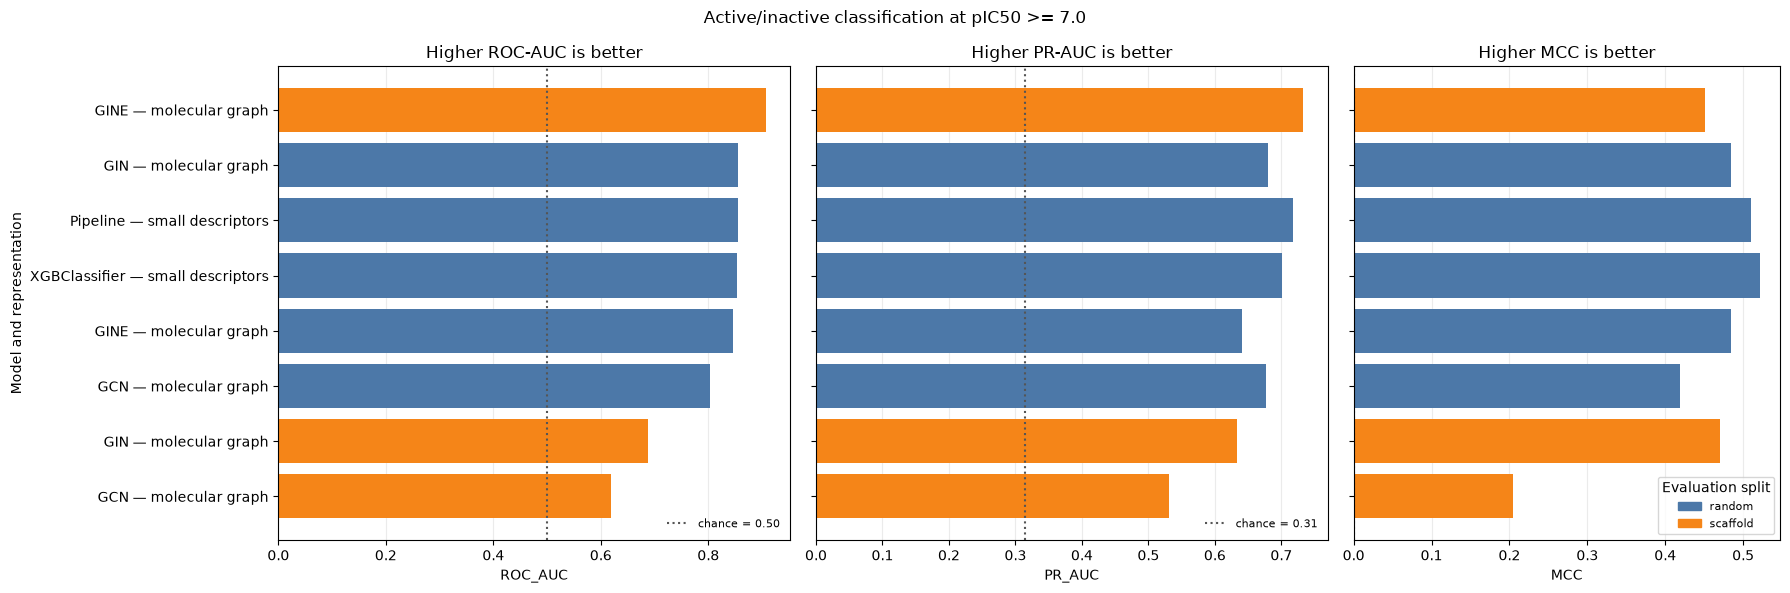

In [92]:
classification_results_df = pd.DataFrame(classification_results).copy()
classification_results_df = classification_results_df.dropna(subset=["ROC_AUC"]).reset_index(drop=True)
display(classification_results_df.sort_values(["Split", "ROC_AUC"],
                                              ascending=[True, False]).reset_index(drop=True))

plot_results = classification_results_df.sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
plot_results["label"] = plot_results.apply(
    lambda row: f"{row['Model']} — {row['Representation']}",
    axis=1,
)
split_colors = {
    "random": "#4C78A8",
    "scaffold": "#F58518",
}
colors = plot_results["Split"].map(split_colors).fillna("#B279A2")
y_positions = np.arange(len(plot_results))
figure_height = max(6, 0.42 * len(plot_results))
figure, axes = plt.subplots(
    1,
    3,
    figsize=(18, figure_height),
    sharey=True,
    gridspec_kw={"width_ratios": [1.2, 1.2, 1.0]},
)

# a classifier is only useful above chance, so draw it
chance_lines = {"ROC_AUC": 0.5, "PR_AUC": float(y_class.mean()), "MCC": 0.0}
for axis, metric, title in zip(
    axes,
    ["ROC_AUC", "PR_AUC", "MCC"],
    ["Higher ROC-AUC is better", "Higher PR-AUC is better", "Higher MCC is better"],
):
    axis.barh(y_positions, plot_results[metric], color=colors)
    axis.axvline(chance_lines[metric], color="#555555", linestyle=":", linewidth=1.5,
                 label=f"chance = {chance_lines[metric]:.2f}")
    axis.set_title(title)
    axis.set_xlabel(metric)
    axis.grid(axis="x", alpha=0.25)
    axis.set_axisbelow(True)
    axis.legend(loc="lower right", fontsize=8, frameon=False)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(plot_results["label"])
axes[0].invert_yaxis()
axes[0].set_ylabel("Model and representation")
from matplotlib.patches import Patch
axes[2].legend(
    handles=[Patch(color=color, label=split) for split, color in split_colors.items()],
    title="Evaluation split",
    loc="lower right",
    fontsize=8,
)
figure.suptitle(f"Active/inactive classification at pIC50 >= {THRESHOLD}")
figure.tight_layout()
plt.show()

# Conclusions

Selected target is D(2) dopamine receptor. Despite having quite a few (2480) IC50 records, only about 900 survived the initial filtering pipeline. 

In the initial pipeline, scaffold splits were not generally usable, and Random Forest regressor with morgan fingerprints showed the best results with RMSE around 1. This is consistent with CHEMBL240 data.

For classification task, activity threshold was selected at pIC50 = 7. This was the mean value of the surviving molecules, making the split roughly 50%/50%. But turning it into classification actually opened the opportunity to benefit from some previously discarded data (those that don't have an exact value for IC50, but rather "larger than" and "lower than" values). Thanks to this, 1200+ molecules were included in training data, and the number of active became around 30%.

In classification, GINE model with scaffold splits showed the best results. But two other scaffold split models performed bad, consistent with previous observations. Random Forest took 3rd place, but the difference between the top 3 models is not large.